In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fastplotlib as fpl

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [237]:
n_timepoints = 1_000
clean = np.zeros(n_timepoints)


x = 0
a = 0.7

b = 0

firing_prop = 0.03
spikes = (np.random.rand(n_timepoints) < firing_prop).astype(float)

for i in range(2, n_timepoints):
    clean[i] = (a * clean[i - 1]) + (b * clean[i - 2]) + (50 * spikes[i])

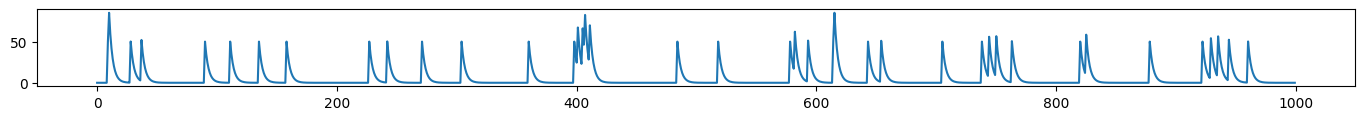

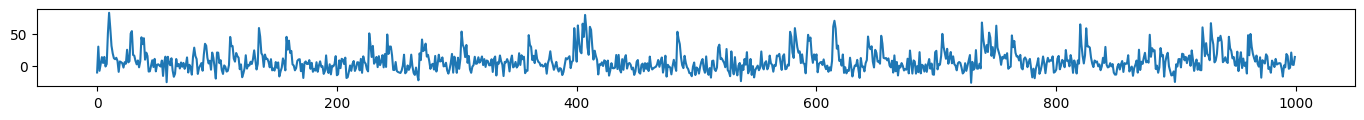

In [290]:
series = clean + np.random.normal(scale=10, size=clean.size)
# series -= series.mean()

fig = plt.figure(figsize=(17, 1))
plt.plot(clean)

fig = plt.figure(figsize=(17, 1))
plt.plot(series)

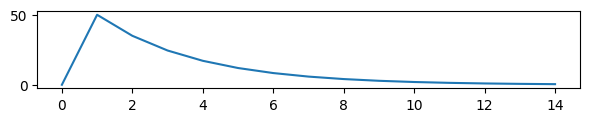

In [291]:
fig = plt.figure(figsize=(7, 1))
plt.plot(clean[110:125])

In [292]:
from scipy import linalg

In [293]:
import seaborn as sns

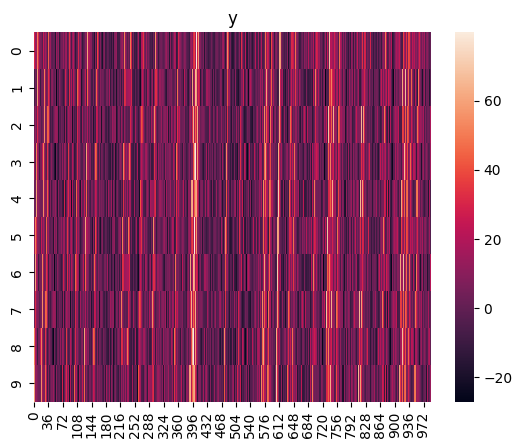

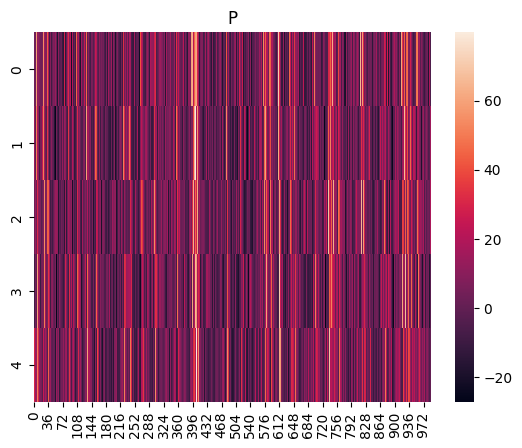

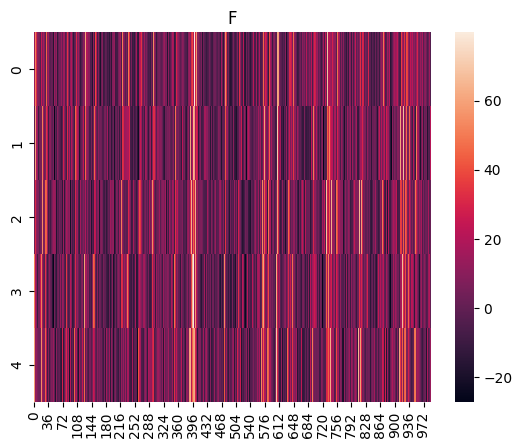

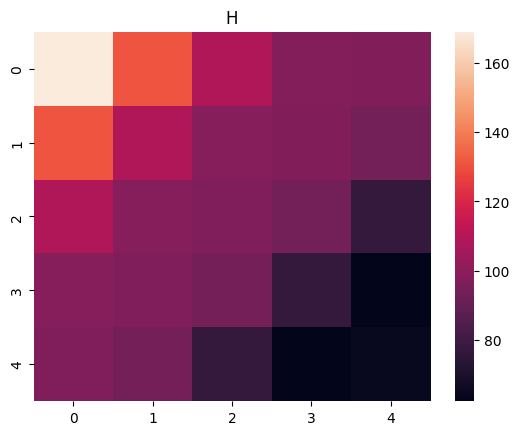

In [326]:
center = 100
w = 10

# Y = linalg.hankel(snip[center - w:center + w], snip[center + w - 1:center + (w * 2)])
Y = linalg.hankel(series[:w], series[w:])

P = np.flipud(Y[:int(w / 2)])
F = Y[int(w/2):]

cov = (F @ P.T) / P.shape[1]

for a, lab in zip([Y, P, F], ["y", "P", "F"]):
    sns.heatmap(a)
    plt.title(lab)
    plt.show()

sns.heatmap(cov)
plt.title("H")
plt.show()

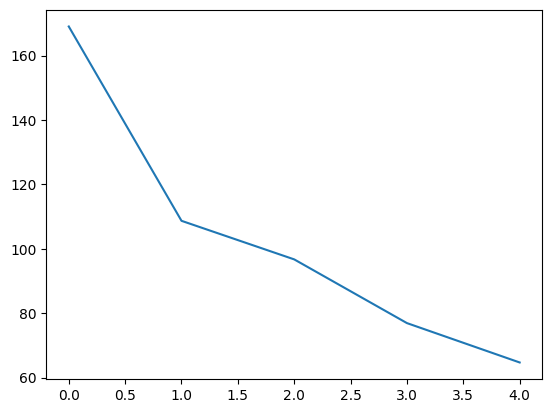

In [327]:
plt.plot(np.diag(cov))

In [328]:
np.diag(cov)

array([169.02452454, 108.67454848,  96.69399592,  76.9080599 ,
        64.68136662])

In [329]:
u, s, v = linalg.svd(cov)

<Axes: >

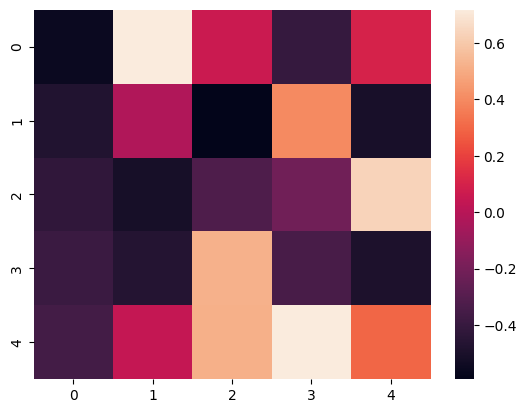

In [330]:
sns.heatmap(u)

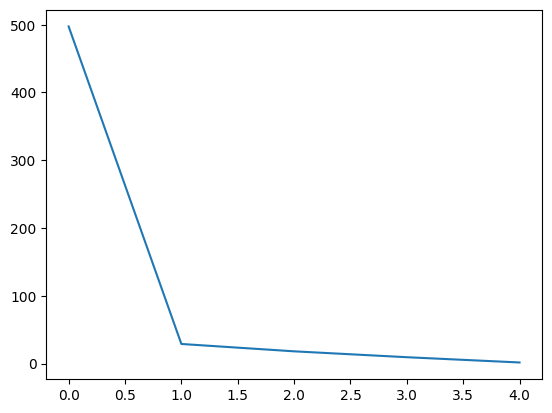

In [331]:
plt.plot(s)

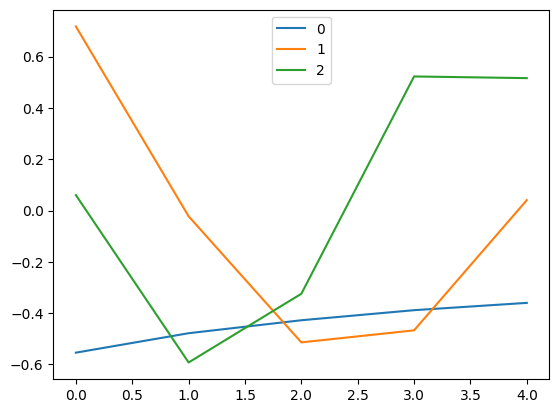

In [332]:
for i in range(3):
    # if i > 0:
    #     continue
    plt.plot(u[:, i], label=str(i))

plt.legend()

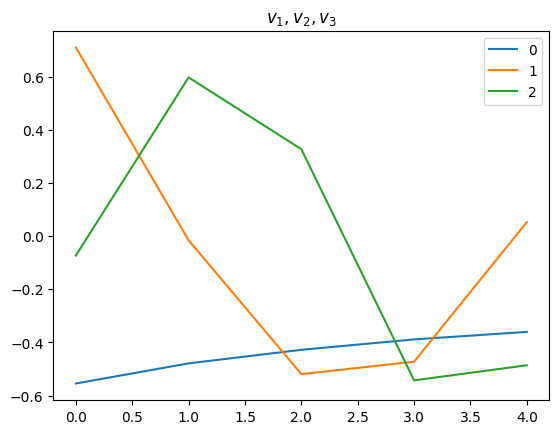

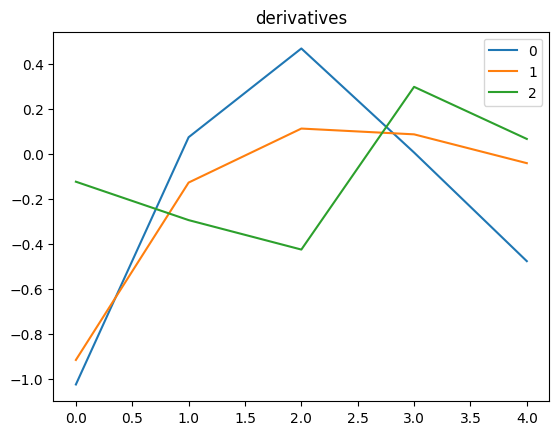

In [333]:
for i in range(3):
    plt.plot(v[i], label=str(i))

plt.title("$v_1, v_2, v_3$")
plt.legend()
plt.show()

grads = np.gradient(np.gradient(v, axis=0), axis=0)
for i in range(3):
    plt.plot(grads[i], label=i)

plt.title("derivatives")
plt.legend()
plt.show()

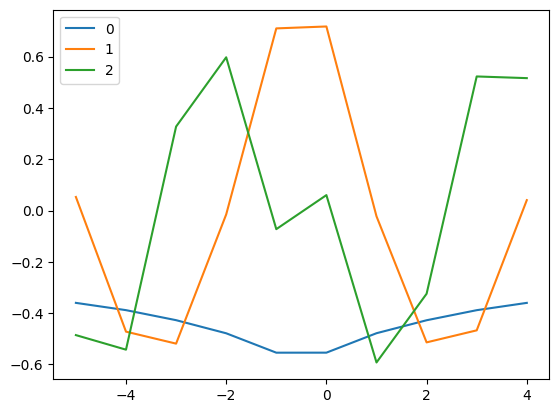

In [334]:
for i in range(3):
    plt.plot(np.arange(-int(w/2), int(w/2)), np.hstack([np.flipud(v[i]), u[:, i]]), label=i)
plt.legend()
plt.show()

In [335]:
from scipy.spatial import distance

In [336]:
distance.cosine(v[1], v[2])

1.0

<Axes: >

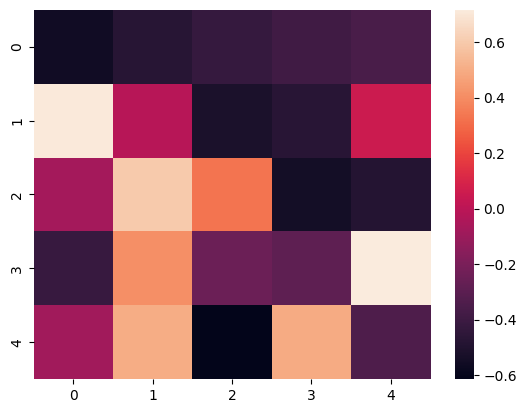

In [337]:
sns.heatmap(v)

In [338]:
from scipy import signal

/home/kushal/venvs/mescore/lib/python3.11/site-packages/scipy/signal/_spectral_py.py:2017: UserWarning: nperseg = 256 is greater than input length  = 5, using nperseg = 5
  warnings.warn('nperseg = {0:d} is greater than input length '


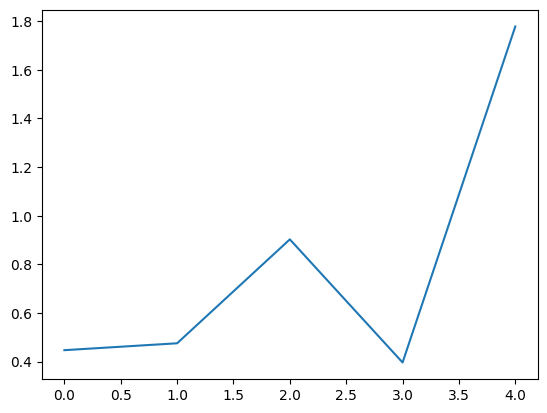

In [339]:
plt.plot(signal.welch(v, axis=0)[1].sum(axis=0))

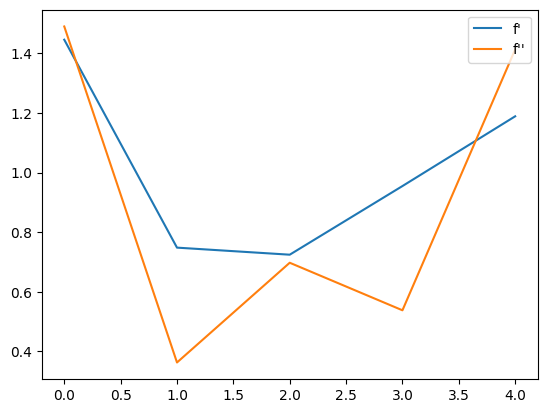

In [340]:
d1 = np.gradient(v, axis=0)
d2 = np.gradient(d1, axis=0)
plt.plot(np.linalg.norm(d1, axis=0), label="f'")
plt.plot(np.linalg.norm(d2, axis=0), label="f''")
plt.legend(loc="upper right")
plt.show()

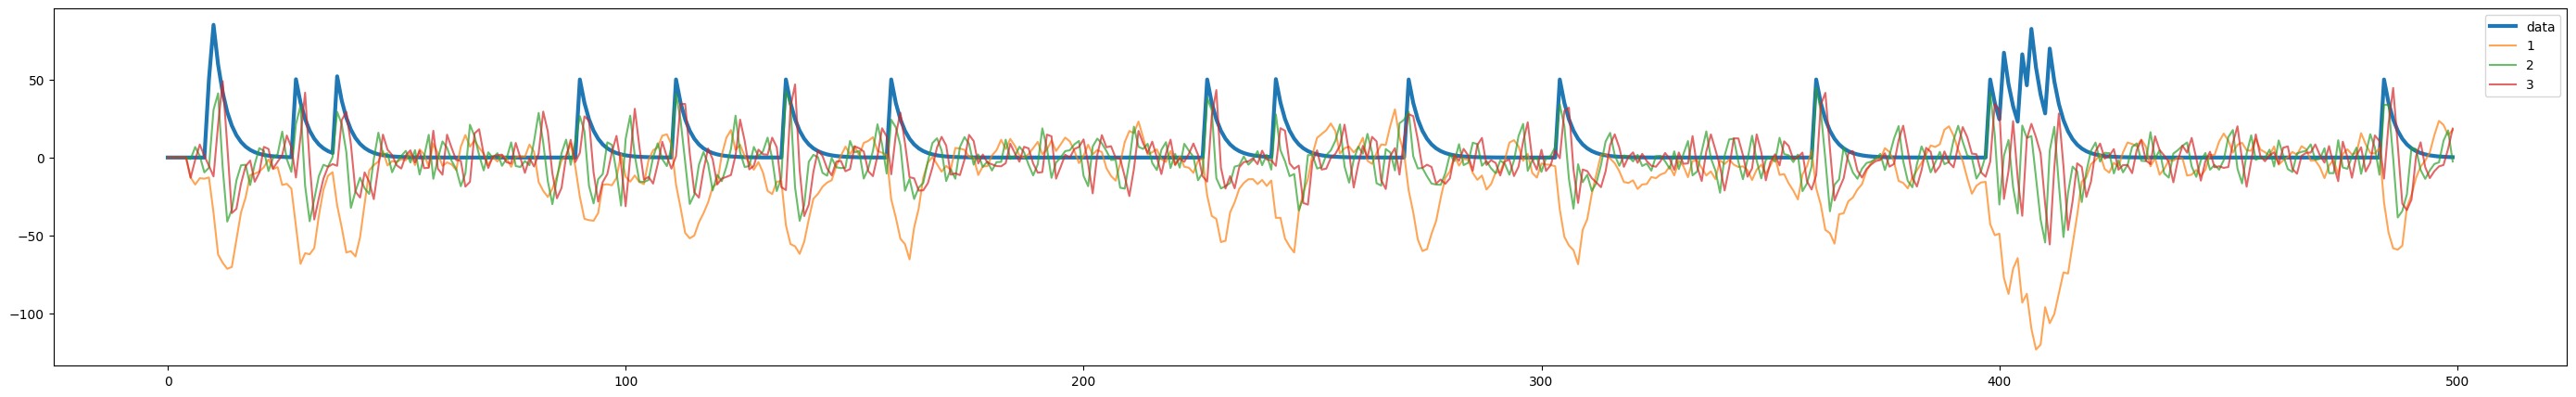

In [341]:
filtered = np.zeros(shape=(3, n_timepoints - int(w/2)))
filtered[:, int(w/2):] = v[:3] @ P

indices = slice(0, 500)
fig = plt.figure(figsize=(35, 5))
plt.plot(clean[indices], label="data", linewidth=3)
for i in range(filtered.shape[0]):
    plt.plot(filtered[i][indices], label=i + 1, alpha=0.7)
plt.legend()
plt.show()

In [260]:
P.shape

(15, 970)

In [113]:
v[:3].shape

(3, 15)

In [114]:
filtered.shape

(3, 220)

# Reconstruct or denoise the entire signal using the kernels? 

In [25]:
P.ptp()

97.00020683091903

In [25]:
pc

array(0.)

In [32]:
cov = np.cov(X)

<Axes: >

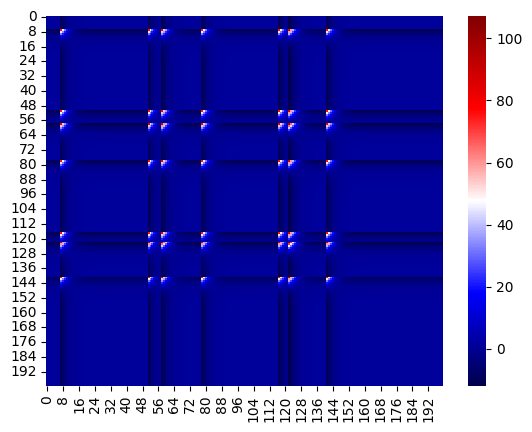

In [33]:
sns.heatmap(cov, cmap="seismic")

# Try this with noise and hankel matrices